# 06 · Decision framework

**The question.** Given a task, which decoder and which settings?

**The claim.** Two questions settle most of it. Is there one right answer? Use greedy or beam search at temperature 0. Is the task open-ended? Use temperature with nucleus sampling, and add a mild repetition penalty only if loops appear. Everything else is tuning inside a usable band, one knob at a time, and a generation problem is often a decoding fix rather than a model change.

**By the end** you will have the rules, the evidence for them from this project's arena, and working decoders to copy.

*Outputs:* `outputs/figures/06_*.png` and `outputs/results/06_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. The rules

| Task | Decoder | Temperature | Why |
|---|---|---|---|
| **One correct answer**: translation, extraction, classification, structured output | greedy, or beam search (B = 4) | 0 | The answer is usually the most probable continuation; sampling only adds ways to be wrong. |
| **Open-ended**: stories, brainstorming, dialogue | nucleus, top-p 0.8–0.95 | 0.7–1.0 | Variety from the plausible options, no absurd tail. |
| **Open-ended and looping** | as above + repetition penalty 1.1–1.3 (or frequency penalty ~0.1) | 0.7–1.0 | Patches the groove; stronger penalties start breaking answers. |

Plus four habits:

1. **Temperature near 0 loops and very high rambles.** The usable band is in between; find it with a sweep, not a default.
2. **Set top-p before top-k.** Top-p adapts to the model's confidence; a fixed k does not.
3. **Tune one knob at a time.** Temperature is applied before top-p, so changing both at once confounds them.
4. **The output is the decoder's choice over the model's distribution.** Loops, rambling, and blandness are often decoding fixes.

In [2]:
from src.evaluation import RECOMMENDATIONS, recommend

save_json("06_rules", RECOMMENDATIONS)
for kind in ("single", "open"):
    rule = recommend(kind)
    print(f"{kind:>6}: use {rule['use']}\n        for {rule['examples']}\n")

single: use greedy or beam search, temperature 0
        for translation, extraction, classification, structured output, arithmetic

  open: use nucleus (top-p 0.8-0.95) with temperature 0.7-1.0; add a repetition penalty if loops appear
        for stories, brainstorming, dialogue, marketing copy



## 2. The evidence: one arena, ten decoders, both kinds of task

In [3]:
import math

from src.datasets import char_prompts
from src.decoders import BeamSearch, Decoder, make_generator
from src.evaluation import (best_decoder, corpus_lexicon, run_arena, standard_strategies,
                            summarize_arena)
from src.model import default_char_lm

model = default_char_lm()
N_NEW = S.generation.max_new_tokens
d = S.decoding
strategies = standard_strategies(S) + [
    BeamSearch(8),
    Decoder(temperature=0.8, top_p=0.9),
    Decoder(temperature=0.8, top_p=0.9, repetition_penalty=1.2),
]
arena = run_arena(model, char_prompts(), strategies, n_samples=S.generation.n_samples,
                  max_new_tokens=N_NEW, seed=SEED, lexicon=corpus_lexicon(), score_quality=False)
summary = summarize_arena(arena, S.generation.n_samples)
winners = {kind: best_decoder(summary, kind) for kind in ("single", "open")}
print(f"single-answer winner: {winners['single']}\nopen-ended winner:    {winners['open']}")
cols = ["single_accuracy", "open_score", "open_distinct_2", "open_valid_words", "open_diversity"]
summary[cols].round(3)

single-answer winner: greedy
open-ended winner:    T=0.8, top-p=0.9, rep=1.2


,single_accuracy,open_score,open_distinct_2,open_valid_words,open_diversity
decoder,,,,,
greedy,1.0,0.359,0.364,0.987,0.073
"greedy, rep=1.3",1.0,0.690,0.699,0.987,0.140
beam (B=4),1.0,0.610,0.612,0.997,0.122
T=1,1.0,0.827,0.911,0.908,0.720
T=2,0.2,0.292,0.998,0.293,0.987
"T=1, top-k=5",1.0,0.829,0.893,0.928,0.725
"T=1, top-p=0.8",1.0,0.852,0.861,0.990,0.658
beam (B=8),1.0,0.762,0.765,0.997,0.153
"T=0.8, top-p=0.9",1.0,0.881,0.889,0.991,0.654


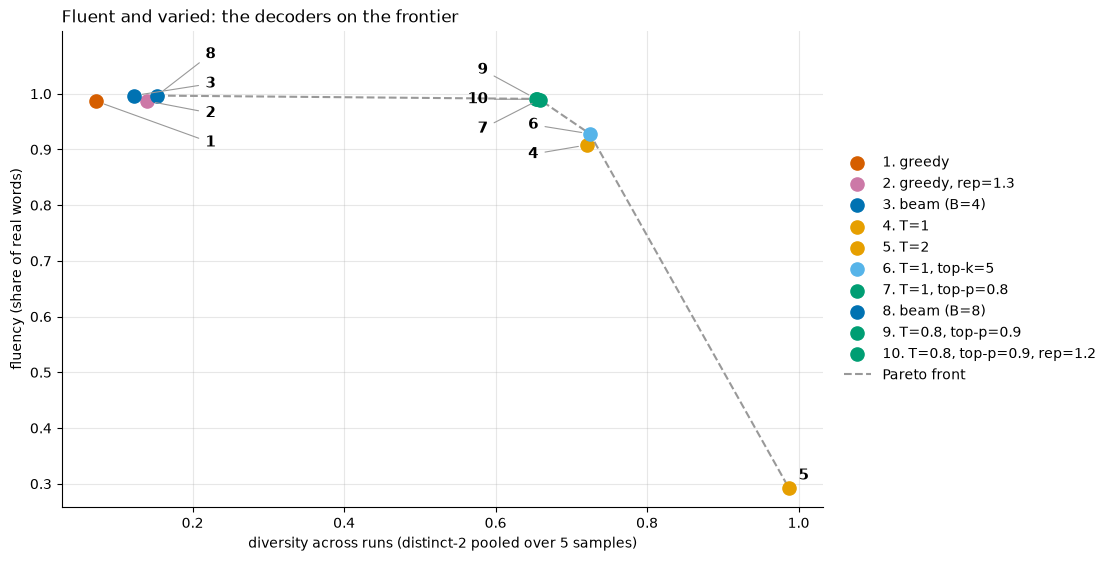

In [4]:
from src.visualisation import plot_quality_diversity

assert winners["single"] in {"greedy", "greedy, rep=1.3", "beam (B=4)", "beam (B=8)"}
assert "top-p" in winners["open"] or "top-k" in winners["open"]
fig = plot_quality_diversity(
    summary, x="open_diversity", y="open_valid_words", front=True,
    xlabel="diversity across runs (distinct-2 pooled over 5 samples)",
    ylabel="fluency (share of real words)",
    title="Fluent and varied: the decoders on the frontier", numbered=True,
)
save_figure(fig, "06_frontier")
save_json("06_arena", {
    "n_samples": S.generation.n_samples, "max_new_tokens": N_NEW, "winners": winners,
    "summary": summary[cols],
    "samples": arena[["prompt", "kind", "decoder", "sample", "completion", "correct"]],
});

Every single-answer decoder that is deterministic scores 100%, and the winner on open-ended prompts is a sampling decoder with a tail cut. Greedy and beam sit far left (one answer, every run); T = 2 sits at the bottom (varied, not words). The frontier runs through the nucleus decoders.

## 3. Nucleus shifts the usable band toward higher temperatures

Sweep temperature twice, once alone and once with top-p = 0.9, and score open-ended text on fluent × varied.

T only         usable band T in [0.25, 1]
T + top-p 0.9  usable band T in [0.5, 1.25]


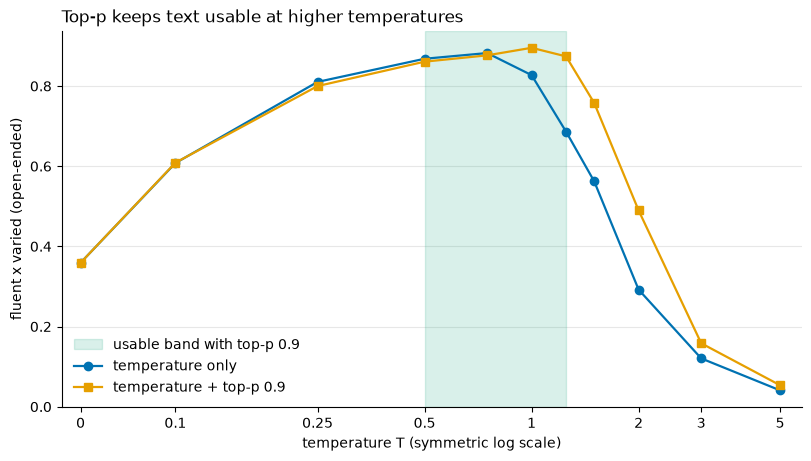

In [5]:
from src.visualisation import plot_metrics_vs

def score_by_temperature(make_decoder):
    sweep = [make_decoder(t) for t in d.temperatures]
    df = run_arena(model, char_prompts("open"), sweep, n_samples=S.generation.n_samples,
                   max_new_tokens=N_NEW, seed=SEED, lexicon=corpus_lexicon(), score_quality=False)
    return summarize_arena(df, S.generation.n_samples)["open_score"].to_numpy()

band_df = pd.DataFrame({
    "temperature": d.temperatures,
    "T only": score_by_temperature(Decoder.sampling),
    "T + top-p 0.9": score_by_temperature(lambda t: Decoder.nucleus(0.9, t)),
})

def usable_band(column):
    ok = band_df.loc[band_df[column] >= 0.9 * band_df[column].max(), "temperature"]
    return float(ok.min()), float(ok.max())

bands = {c: usable_band(c) for c in ("T only", "T + top-p 0.9")}
for name, (lo, hi) in bands.items():
    print(f"{name:14s} usable band T in [{lo:g}, {hi:g}]")
fig = plot_metrics_vs(
    band_df, "temperature", {"T only": "temperature only", "T + top-p 0.9": "temperature + top-p 0.9"},
    xlabel="temperature T (symmetric log scale)", ylabel="fluent x varied (open-ended)",
    title="Top-p keeps text usable at higher temperatures", logx=True,
    band=bands["T + top-p 0.9"], band_label="usable band with top-p 0.9",
)
save_figure(fig, "06_top_p_shifts_band")
save_json("06_top_p_shifts_band", {"band_rule": "within 10% of the best score", "bands": bands,
                                   "scores": band_df});

The gain is all at the top end. At T = 1.25 top-p scores 0.87 against 0.69 for plain sampling, and at T = 1.5-2 it recovers a large part of the damage, because the tail that high temperature inflates is cut away. At low temperature the two curves are within 0.01 of each other; the band's lower edge moves up only because the top-p curve peaks higher, which raises the "within 10% of the best" threshold. So top-p does not make low temperatures worse, it makes high temperatures survivable. "Temperature 0.7-0.8 with top-p 0.9" sits inside the band with margin on both sides, which is why it works as a default.

## 4. Penalties: the loop patch, and its price

,penalty,greedy_distinct_2,greedy_accuracy,nucleus_score,nucleus_accuracy
0,1.0,0.364,1.000,0.852,1.000
1,1.1,0.600,1.000,0.879,1.000
2,1.2,0.655,1.000,0.896,1.000
3,1.3,0.699,1.000,0.867,0.933
4,1.5,0.815,0.833,0.820,0.700
5,2.0,0.523,0.333,0.575,0.133


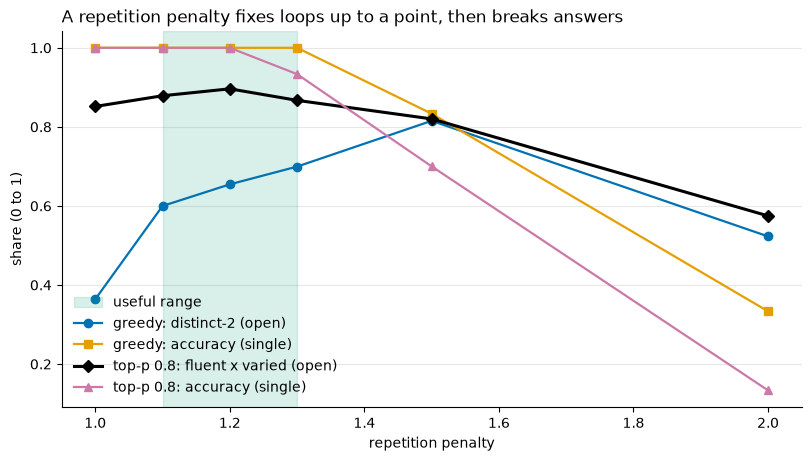

In [6]:
pen_strategies = []
for r in d.repetition_penalties:
    pen_strategies += [Decoder.greedy(r), Decoder(temperature=1.0, top_p=0.8, repetition_penalty=r)]
pen = summarize_arena(
    run_arena(model, char_prompts(), pen_strategies, n_samples=S.generation.n_samples,
              max_new_tokens=N_NEW, seed=SEED, lexicon=corpus_lexicon(), score_quality=False),
    S.generation.n_samples,
)
greedy_rows = pen.iloc[0::2].reset_index(drop=True)
nucleus_rows = pen.iloc[1::2].reset_index(drop=True)
pen_df = pd.DataFrame({
    "penalty": d.repetition_penalties,
    "greedy_distinct_2": greedy_rows["open_distinct_2"],
    "greedy_accuracy": greedy_rows["single_accuracy"],
    "nucleus_score": nucleus_rows["open_score"],
    "nucleus_accuracy": nucleus_rows["single_accuracy"],
})
fig = plot_metrics_vs(
    pen_df, "penalty",
    {"greedy_distinct_2": "greedy: distinct-2 (open)",
     "greedy_accuracy": "greedy: accuracy (single)",
     "nucleus_score": "top-p 0.8: fluent x varied (open)",
     "nucleus_accuracy": "top-p 0.8: accuracy (single)"},
    xlabel="repetition penalty", ylabel="share (0 to 1)", band=(1.1, 1.3),
    band_label="useful range", legend_loc="lower left",
    title="A repetition penalty fixes loops up to a point, then breaks answers",
)
save_figure(fig, "06_penalty_sweep")
save_json("06_penalty_sweep", {"by_penalty": pen_df, "summary": pen});
pen_df.round(3)

Up to 1.2 a repetition penalty buys a large drop in repetition for free on both decoders. At 1.3 the sampled decoder already starts missing answers, and beyond that the bill arrives for both: accuracy on single-answer prompts falls, because the penalty applies to every token already in the context, *prompt included*, and the answer's letters are in the prompt. At 2.0 greedy even finds a new loop among the characters it is still allowed to use. (`transformers` exposes `prompt_ignore_length` on its repetition processor for exactly this reason.)

The additive OpenAI-style penalties are a gentler alternative:

In [7]:
alt = [Decoder.greedy(), Decoder(temperature=0.0, presence_penalty=0.5),
       Decoder(temperature=0.0, frequency_penalty=0.1), Decoder(temperature=0.0, frequency_penalty=0.3),
       Decoder.greedy(1.3)]
alt_summary = summarize_arena(
    run_arena(model, char_prompts(), alt, n_samples=1, max_new_tokens=N_NEW, seed=SEED,
              lexicon=corpus_lexicon(), score_quality=False), 1,
)[["open_distinct_2", "open_valid_words", "single_accuracy"]]
save_json("06_presence_frequency", alt_summary)
alt_summary.round(3)

,open_distinct_2,open_valid_words,single_accuracy
decoder,,,
greedy,0.364,0.987,1.0
"greedy, presence=0.5",0.521,0.987,1.0
"greedy, freq=0.1",0.702,0.997,1.0
"greedy, freq=0.3",0.937,0.721,1.0
"greedy, rep=1.3",0.699,0.987,1.0


A small frequency penalty (0.1) breaks greedy's loop about as well as a 1.3 repetition penalty with no loss of fluency or accuracy here; at 0.3 it starts to cost real words. Same lesson: penalties are a patch with a useful range, not a dial to max out.

## 5. Copy these

In [8]:
SINGLE_ANSWER = Decoder.greedy()                                      # or BeamSearch(4)
OPEN_ENDED = Decoder(temperature=0.8, top_p=0.9)
OPEN_ENDED_LOOPING = Decoder(temperature=0.8, top_p=0.9, repetition_penalty=1.2)
for name, dec in [("SINGLE_ANSWER", SINGLE_ANSWER), ("OPEN_ENDED", OPEN_ENDED),
                  ("OPEN_ENDED_LOOPING", OPEN_ENDED_LOOPING)]:
    print(f"{name:20s} {dec.label}")

SINGLE_ANSWER        greedy
OPEN_ENDED           T=0.8, top-p=0.9
OPEN_ENDED_LOOPING   T=0.8, top-p=0.9, rep=1.2


And on the real model, each prompt with the decoder the rules prescribe:

In [9]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

In [10]:
from src.datasets import hf_prompts

demo = []
for p, dec in [(hf_prompts("single")[0], SINGLE_ANSWER), (hf_prompts("single")[1], SINGLE_ANSWER),
               (hf_prompts("open")[0], OPEN_ENDED), (hf_prompts("open")[1], OPEN_ENDED_LOOPING)]:
    ids = hf.encode(p.text)
    budget = 4 if p.kind == "single" else 50
    out = dec.generate(hf, ids, budget, eos_token_id=hf.eos_token_id, generator=make_generator(SEED))
    text = hf.decode(out[0, ids.size(1):])
    demo.append({"prompt": p.text, "kind": p.kind, "decoder": dec.label, "completion": text,
                 "correct": p.is_correct(text)})
    print(f"[{p.kind} | {dec.label}]\n{textwrap.fill(p.text + text, 110)}\n")
save_json("06_distilgpt2_recommended", {"model": hf.name, "results": demo});

[single | greedy]
Monday, Tuesday, Wednesday, Thursday, Friday,



[single | greedy]
January, February, March, April, May,



[open | T=0.8, top-p=0.9]
In the morning, the sea was solid and the water was nice.  When I approached the boat, I felt a sense of calm.
The passengers were off to a different boat. The safety of the boat was made more important. Some of the
passengers were simply in their



[open | T=0.8, top-p=0.9, rep=1.2]
Once upon a time, in a small village by the sea, I would first work with my mother and sister. My father was
always working hard for me to help her but if they found it difficult enough not to take care of you or your
family members who were there when we left our house without paying taxes on



## The decoder decides

A language model produces one thing: a fixed distribution over the next token. Across these six notebooks, without touching a single weight, that distribution was turned into a repeating loop (greedy), word salad (high temperature), fluent and varied text (temperature plus nucleus), and safe, identical-every-time text (beam search). Each of those is a few lines of sampler code, each was measured rather than eyeballed, and each was checked against `transformers`.

So when generated text loops, rambles, or bores, look at the decoder first. It is ten lines you can read, and it is the part of the system that decides what your model says.

**Where next** (from the PRD's future extensions): typical and contrastive decoding, constrained decoding for valid JSON (`tokenization_101`), speculative decoding, self-consistency sampling for reasoning, and using logprobs for confidence (`calibration_arena`).